In [2]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
#FETCH DATA

In [4]:
from ucimlrepo import fetch_ucirepo 
   
online_retail = fetch_ucirepo(id=352) 
  
X = online_retail.data.features 
y = online_retail.data.targets 
   
print(online_retail.metadata) 
   
print(online_retail.variables) 


{'uci_id': 352, 'name': 'Online Retail', 'repository_url': 'https://archive.ics.uci.edu/dataset/352/online+retail', 'data_url': 'https://archive.ics.uci.edu/static/public/352/data.csv', 'abstract': 'This is a transactional data set which contains all the transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail.', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate', 'Sequential', 'Time-Series'], 'num_instances': 541909, 'num_features': 6, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': None, 'index_col': ['InvoiceNo', 'StockCode'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2015, 'last_updated': 'Mon Oct 21 2024', 'dataset_doi': '10.24432/C5BW33', 'creators': ['Daqing Chen'], 'intro_paper': {'ID': 361, 'type': 'NATIVE', 'title': 'Data mining for the online retail industry: A case study of RFM model-based customer segmenta

In [5]:
#DATA AS DATAFRAMES

In [6]:
import pandas as pd

df = online_retail.data.original.copy()


print(df.shape)
print(df.columns.tolist())
display(df.head())

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())

(541909, 8)
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


Dataset loaded successfully!
Shape: (541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  


In [7]:
#IDENTIFYING DUPLICATES

In [8]:
duplicate_rows = df[df.duplicated(keep=False)]

print("Duplicate copies:", df.duplicated().sum())

print("All rows involved in duplicates:", len(duplicate_rows))

display(duplicate_rows.head(10))

Duplicate copies: 5268
All rows involved in duplicates: 10147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom


In [9]:
df_clean = df.drop_duplicates().copy()
print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))
print("Duplicate copies removed:", len(df) - len(df_clean))
print("Remaining exact duplicates:", df_clean.duplicated().sum())

Original rows: 541909
Rows after removing duplicates: 536641
Duplicate copies removed: 5268
Remaining exact duplicates: 0


In [10]:
#IDENTIFYING MISSING VALUES

In [11]:
print(df_clean.isnull().sum())

print("\nTotal missing values:", df_clean.isnull().sum().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

Total missing values: 136491


In [12]:
#FILLING MISSING VALUES OF DESCRIPTION FROM STOCK CODE

In [14]:
stock_description = (
    df_clean.dropna(subset=['Description'])
    .drop_duplicates(subset=['StockCode'])
    .set_index('StockCode')['Description']
)

In [15]:
df_clean['Description'] = df_clean['Description'].fillna(
    df_clean['StockCode'].map(stock_description)
)

In [16]:
print("Missing descriptions after filling:",
      df_clean['Description'].isnull().sum())

Missing descriptions after filling: 112


In [18]:
df_clean.dropna(subset=['Description'])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France


In [19]:
print(df_clean.isnull().sum())

print("\nTotal missing values:", df_clean.isnull().sum().sum())

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     134925
Country             0
dtype: int64

Total missing values: 134925


In [20]:
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]

In [34]:
#IDENTIFYING CANCELLED TRANSACTIONS

In [22]:
cancelled = df_clean[
    df_clean['InvoiceNo'].astype(str).str.startswith('C')
].copy()

print("Cancelled transaction rows:", len(cancelled))
display(cancelled.head())

Cancelled transaction rows: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country


In [38]:
#IDENTIFYING NON CANCELLED INVOICES

In [23]:
df_sales = df_clean[
    ~df_clean['InvoiceNo'].astype(str).str.startswith('C')
].copy()

print("Rows before separation:", len(df_clean))
print("Cancelled rows:", len(cancelled))
print("Non-cancelled rows:", len(df_sales))
print("Total after separation:", len(cancelled) + len(df_sales))

Rows before separation: 524878
Cancelled rows: 0
Non-cancelled rows: 524878
Total after separation: 524878


In [25]:
df_clean.to_csv('online_retail_cleaned.csv', index=False)

In [40]:
#CALCULATING REVENUE

In [24]:
pip install matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

df_monthly = df_clean.copy()

df_monthly['InvoiceDate'] = pd.to_datetime(
    df_monthly['InvoiceDate'], errors='coerce'
)

df_monthly['Revenue'] = (
    df_monthly['Quantity'] * df_monthly['UnitPrice']
)

display(df_monthly.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [28]:
monthly_revenue = (
    df_monthly
    .dropna(subset=['InvoiceDate'])
    .groupby(df_monthly['InvoiceDate'].dt.to_period('M'))['Revenue']
    .sum()
)

monthly_revenue.index = monthly_revenue.index.astype(str)

display(monthly_revenue)

InvoiceDate
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Name: Revenue, dtype: float64

In [52]:
#PLOT MONTHLY REVENUE

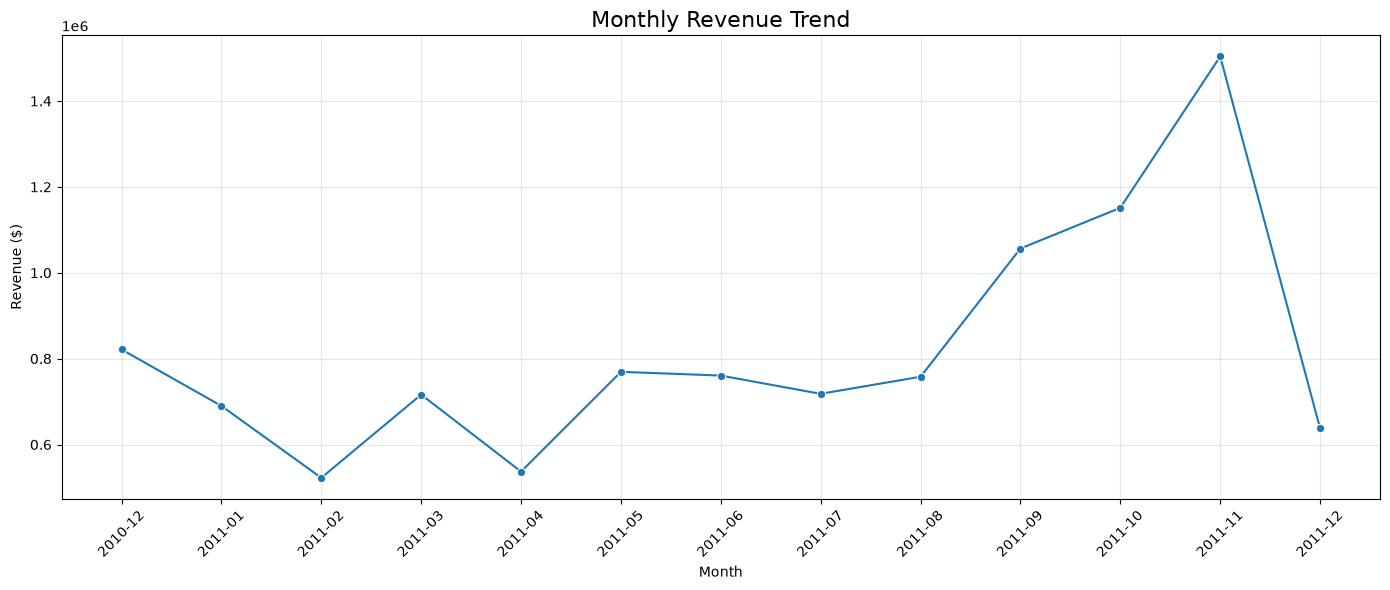

In [29]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    x=monthly_revenue.index,
    y=monthly_revenue.values,
    marker='o'
)

plt.title('Monthly Revenue Trend', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Revenue ($)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [54]:
#HIGHEST REVENUE MONTH

In [30]:
print("Highest revenue month:", monthly_revenue.idxmax())
print("Highest monthly revenue: $",
      round(monthly_revenue.max(), 2))

print("Lowest revenue month:", monthly_revenue.idxmin())
print("Lowest monthly revenue: $",
      round(monthly_revenue.min(), 2))

Highest revenue month: 2011-11
Highest monthly revenue: $ 1503866.78
Lowest revenue month: 2011-02
Lowest monthly revenue: $ 522545.56


In [64]:
#NET QUANTITY PER PRODUCT

In [31]:
import pandas as pd

df_products = df_clean.copy()

df_products['Quantity'] = pd.to_numeric(
    df_products['Quantity'], errors='coerce'
)

top_products = (
    df_products.groupby('StockCode')['Quantity']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 products by net quantity:")
display(top_products.head(10))

Top 10 products by net quantity:


StockCode
23843     80995
23166     78033
22197     56898
84077     54951
85099B    48371
85123A    37641
21212     36396
84879     36362
23084     30739
22492     26633
Name: Quantity, dtype: int64

In [66]:
#TOP 10 PRODUCTS

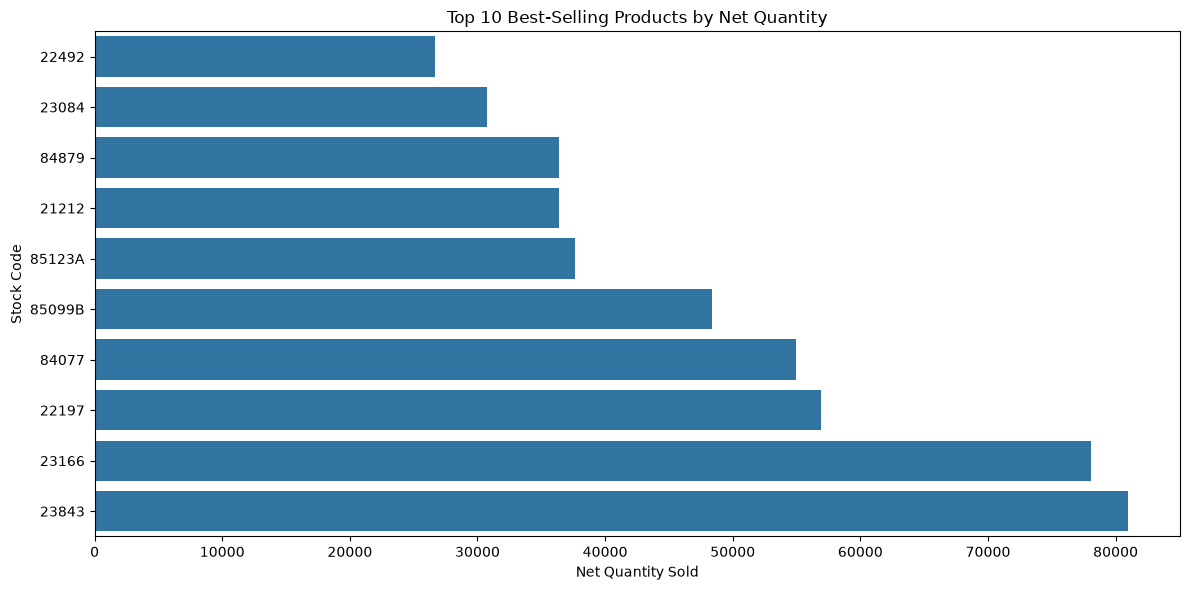

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

top_10 = top_products.head(10).sort_values()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10.values,
    y=top_10.index.astype(str)
)

plt.title('Top 10 Best-Selling Products by Net Quantity')
plt.xlabel('Net Quantity Sold')
plt.ylabel('Stock Code')
plt.tight_layout()
plt.show()

In [34]:
top_10_table = top_products.head(10).rename(
    'NetQuantity'
).reset_index()

top_10_table['Description'] = (
    top_10_table['StockCode'].map(stock_description)
)

display(top_10_table)

,StockCode,NetQuantity,Description
0,23843,80995,"PAPER CRAFT , LITTLE BIRDIE"
1,23166,78033,MEDIUM CERAMIC TOP STORAGE JAR
2,22197,56898,SMALL POPCORN HOLDER
3,84077,54951,WORLD WAR 2 GLIDERS ASSTD DESIGNS
4,85099B,48371,JUMBO BAG RED RETROSPOT
5,85123A,37641,WHITE HANGING HEART T-LIGHT HOLDER
6,21212,36396,PACK OF 72 RETROSPOT CAKE CASES
7,84879,36362,ASSORTED COLOUR BIRD ORNAMENT
8,23084,30739,RABBIT NIGHT LIGHT
9,22492,26633,MINI PAINT SET VINTAGE


In [69]:
#PURCHASE FREQUENCY 

In [35]:
df_frequency = df_clean.copy()

df_frequency = df_frequency.dropna(subset=['CustomerID'])

purchase_frequency = (
    df_frequency.groupby('CustomerID')['InvoiceNo']
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 customers by purchase frequency:")
display(purchase_frequency.head(10))

Top 10 customers by purchase frequency:


CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64

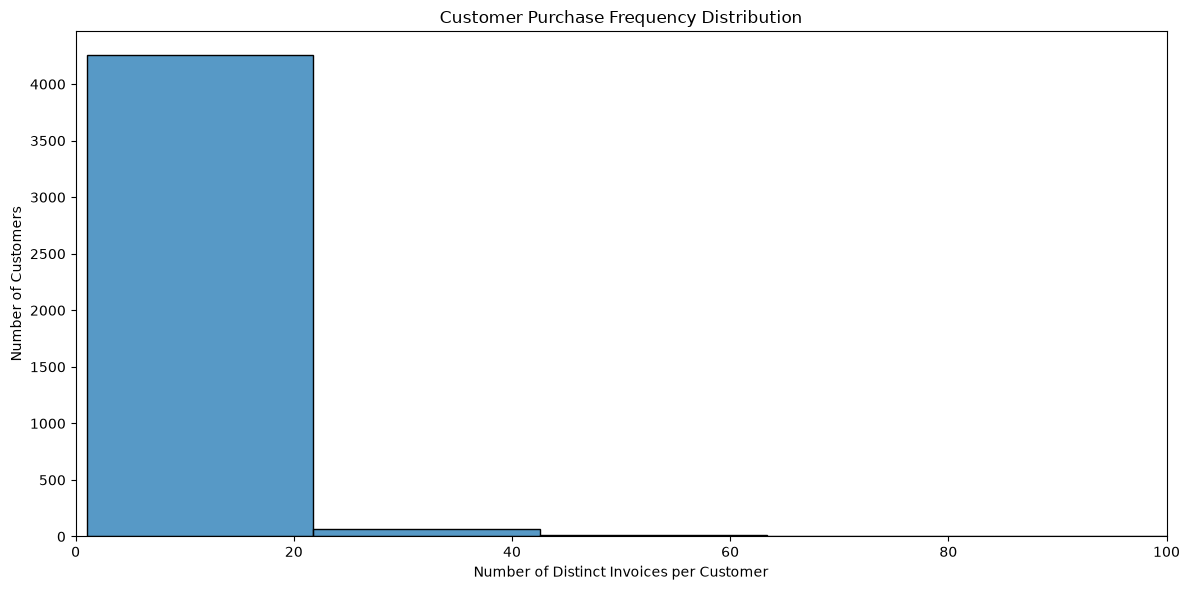

In [64]:
frequency_counts = purchase_frequency.value_counts().sort_index()

plt.figure(figsize=(12, 6))

sns.histplot(
    purchase_frequency,
    bins=10
)

plt.title('Customer Purchase Frequency Distribution')
plt.xlabel('Number of Distinct Invoices per Customer')
plt.ylabel('Number of Customers')
plt.xlim(0,100)
plt.tight_layout()
plt.show()

In [37]:
print("Unique customers:", purchase_frequency.count())

print("Maximum invoices for one customer:", purchase_frequency.max())

Unique customers: 4338
Maximum invoices for one customer: 209


In [77]:
#REVENUE BY COUNTRY

In [38]:
import pandas as pd

df_country = df_clean.copy()

df_country['Revenue'] = (
    df_country['Quantity'] * df_country['UnitPrice']
)

country_revenue = (
    df_country.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

display(country_revenue)

Country
United Kingdom          9001744.094
Netherlands              285446.340
EIRE                     283140.520
Germany                  228678.400
France                   209625.370
Australia                138453.810
Spain                     61558.560
Switzerland               57067.600
Belgium                   41196.340
Sweden                    38367.830
Japan                     37416.370
Norway                    36165.440
Portugal                  33683.050
Finland                   22546.080
Singapore                 21279.290
Channel Islands           20440.540
Denmark                   18955.340
Italy                     17483.240
Hong Kong                 15483.000
Cyprus                    13502.850
Austria                   10198.680
Israel                     8129.410
Poland                     7334.650
Greece                     4760.520
Unspecified                4740.940
Iceland                    4310.000
Canada                     3666.380
USA                 

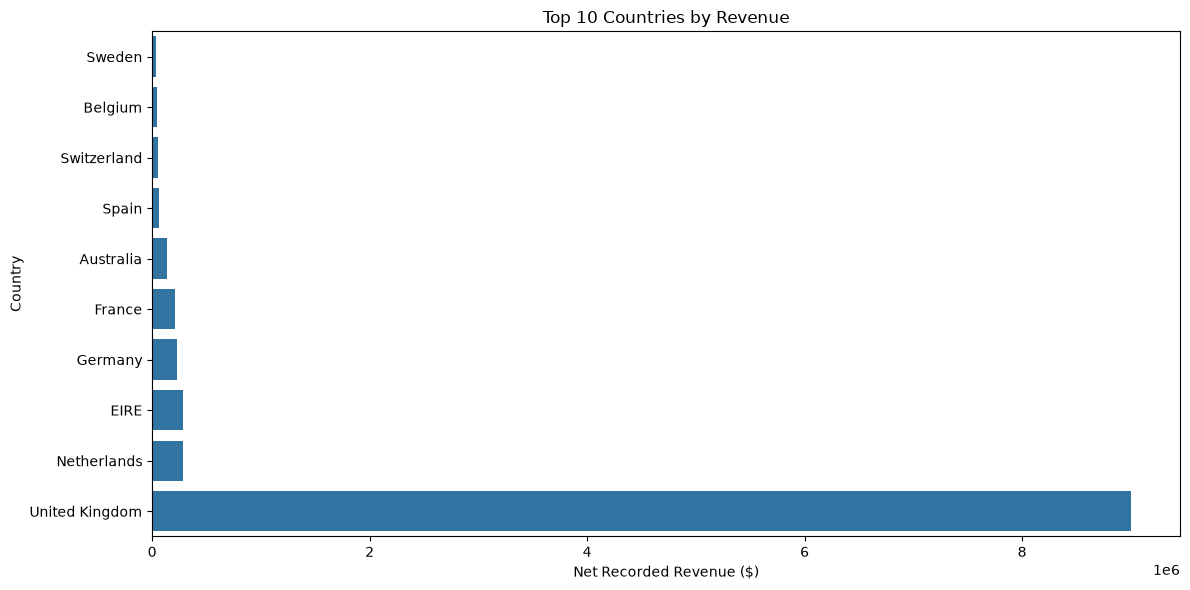

In [39]:
top_10_countries = country_revenue.head(10).sort_values()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_countries.values,
    y=top_10_countries.index
)

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Net Recorded Revenue ($)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

In [40]:
print("Highest-revenue country:", country_revenue.idxmax())
print(f"Revenue: ${country_revenue.max():,.2f}")

Highest-revenue country: United Kingdom
Revenue: $9,001,744.09


In [41]:
#DATA PREPEARING FOR RFM(RECENCY,FREQUENCY,MONETRY)

In [42]:
df_rfm = df_clean.dropna(subset=['CustomerID']).copy()

In [44]:
df_rfm['TotalAmount'] = df_rfm['Quantity'] * df_rfm['UnitPrice']

In [48]:
df_rfm['InvoiceDate'] = pd.to_datetime(df_rfm['InvoiceDate'])

In [49]:
reference_date = df_rfm['InvoiceDate'].max() + pd.Timedelta(days=1)

In [50]:
rfm = df_rfm.groupby('CustomerID').agg(Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days), Frequency=('InvoiceNo', 'nunique'), Monetary=('TotalAmount', 'sum')).reset_index()

In [52]:
rfm.head(10)

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40
5,12352.0,36,8,2506.04
6,12353.0,204,1,89.00
7,12354.0,232,1,1079.40
8,12355.0,214,1,459.40
9,12356.0,23,3,2811.43


In [53]:
rfm[['Recency', 'Frequency', 'Monetary']].describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [74]:
import numpy as np

rfm['Segment'] = np.select(
    [
        (rfm['Recency'] <= 51) & (rfm['Frequency'] >= 5) & (rfm['Monetary'] >= 668.57),
        (rfm['Recency'] <= 51) & (rfm['Frequency'] >= 5),
        (rfm['Recency'] <= 51) & (rfm['Frequency'] < 5),
        (rfm['Recency'] > 51) & (rfm['Frequency'] >= 5),
        (rfm['Recency'] > 51) & (rfm['Frequency'] < 5)
    ],
    [
        'Champions',
        'Loyal Customers',
        'Potential Loyalists',
        'At Risk',
        'Lost Customers'
    ],
    default='Other'
)

In [75]:
segment_counts = rfm['Segment'].value_counts()

print(segment_counts)

Segment
Lost Customers         1970
Potential Loyalists    1254
Champions               921
At Risk                 180
Loyal Customers          13
Name: count, dtype: int64


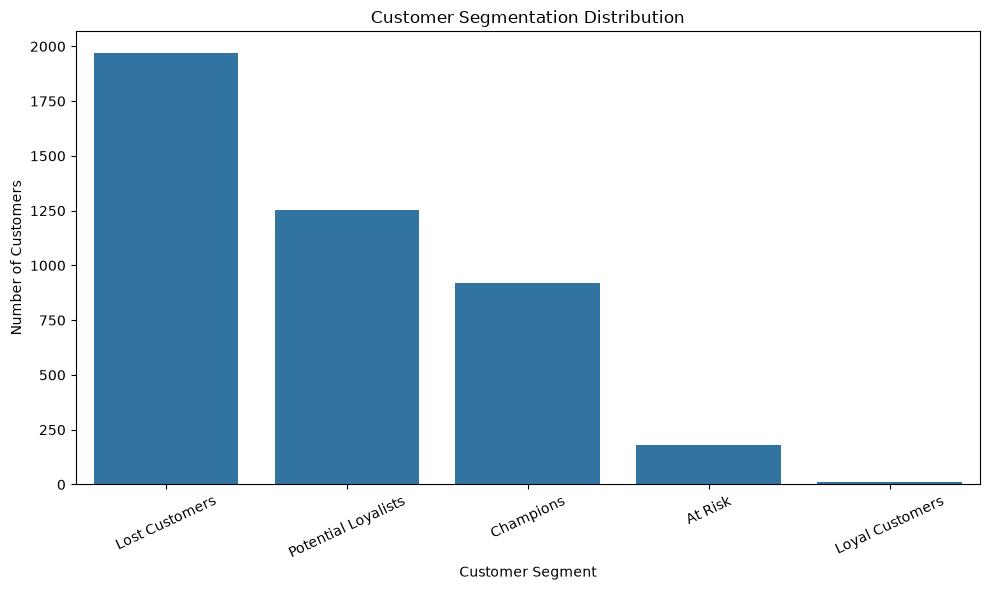

In [76]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=rfm,
    x='Segment',
    order=rfm['Segment'].value_counts().index
)

plt.title('Customer Segmentation Distribution')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [71]:
#K_MEANS

In [73]:
!pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp311-cp311-win_amd64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl (36.6 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ ---------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [77]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler